In [ ]:
# ===========================
# LAB được chạy trên gg colab
# ===========================


from google.colab import drive
import os, shutil, zipfile

drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/VinaFood21.zip"
LOCAL_ROOT = "/content/VinaFood21"

if not os.path.isdir(f"{LOCAL_ROOT}/train"):
    shutil.copy(ZIP_PATH, "/content/VinaFood21.zip")      # 1 file lớn -> nhanh
    with zipfile.ZipFile("/content/VinaFood21.zip") as z:
        z.extractall("/content")                            # giải nén ra ổ local
    os.remove("/content/VinaFood21.zip")
print(os.listdir(LOCAL_ROOT))   # phải thấy ['train', 'test'] (hoặc thêm 'val')

Mounted at /content/drive
['README.txt', 'test', 'train']


In [2]:
import time
import math
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns



# Cố định seed 42
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.11.0+cu130
device : cuda


In [3]:
# Cấu hình chung cho cả bốn bài: đường dẫn, kích thước ảnh, batch size, seed
DATA_ROOT = Path("/content/VinaFood21")
IMG_SIZE = 64
BATCH = 32
SEED = 42

HAS_DATA = (DATA_ROOT / "train").is_dir()
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

EPOCHS = 10
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


Tìm thấy dữ liệu: True - /content/VinaFood21


In [4]:
# Hai hàm tiện ích dùng lại trong cả bài
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

In [5]:
from torch.utils.data import Subset, random_split

# Hàm tạo DataLoader theo kích thước ảnh
def get_dataloaders(IMG_SIZE, HAS_TV=True):
    # 1. Dựng hai bộ transform riêng cho train và val/test
    if HAS_TV:
        train_tf = transforms.Compose([
            transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
    else:
        train_tf = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])

    eval_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    print(f"Đã dựng train_tf (augment={HAS_TV}) và eval_tf với cỡ ảnh {IMG_SIZE}x{IMG_SIZE}.")

    # 2. Load dataset gốc để lấy danh sách tên lớp chuẩn theo bảng chữ cái
    base_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    classes = base_train.classes

    # 3. Kiểm tra thư mục val/: nếu có sẵn thì load, nếu chưa có thì tự tách từ train/
    val_dir = DATA_ROOT / "val"
    if val_dir.is_dir():
        train_ds = base_train
        val_ds = datasets.ImageFolder(val_dir, transform=eval_tf)
    else:
        print("Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...")
        base_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)

        n_total = len(base_train)
        n_val = int(0.1 * n_total)
        n_train = n_total - n_val

        # Chia ngẫu nhiên cố định seed 42
        g = torch.Generator().manual_seed(SEED)
        tr_split, va_split = random_split(range(n_total), [n_train, n_val], generator=g)

        # Bọc bằng Subset để tập train có augment còn tập val giữ nguyên eval_tf
        train_ds = Subset(base_train, tr_split.indices)
        val_ds = Subset(base_eval, va_split.indices)

    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)

    # 4. Tạo DataLoader
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_dl   = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2)
    test_dl  = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2)

    print(f"Số lớp: {len(classes)} | Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")
    return train_dl, val_dl, test_dl, classes

In [6]:
# Hai hàm huấn luyện và đánh giá dùng chung
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

@torch.no_grad()

def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

# Hàm chạy vòng lặp huấn luyện, vẽ đồ thị và in 4 độ đo
def run_experiment(model, train_dl, val_dl, test_dl, classes, lr=1e-3, epochs=EPOCHS, title="Model"):
    print(f"\n==================== {title} ====================")
    print("Tổng tham số         :", f"{n_params(model):,}")
    print("Tham số được cập nhật:", f"{n_params(model, trainable_only=True):,}")
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    lich_su = []
    start_time = time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        lich_su.append((ep, tr_loss, va_loss))
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}   val {va_loss:.4f}/{va_acc:.4f}")

    sec_per_epoch = (time.time() - start_time) / epochs
    print(f"Thời gian trung bình : {sec_per_epoch:.2f} giây/epoch")

    # Vẽ đường loss train và val
    ep, tr, va = zip(*lich_su)
    plt.figure(figsize=(6, 4))
    plt.plot(ep, tr, label="train loss")
    plt.plot(ep, va, label="val loss")
    plt.title(f"Loss - {title}")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()

    # Đánh giá trên tập test với 4 độ đo
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0)

    print(f"\n--- Kết quả trên tập Test ({title}) ---")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"Macro-F1  : {f1:.4f}\n")
    print("Bảng F1 từng lớp:")
    print(classification_report(y_true, y_pred, target_names=classes, digits=4, zero_division=0))

    # Vẽ Confusion Matrix 21x21
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap="Blues", annot=False)
    plt.title(f"Confusion Matrix - {title}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()
    return f1


In [ ]:
# ===============================
# BÀI 1: XÂY DỰNG MÔ HÌNH LENET-5
# ===============================
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá

class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

In [ ]:
# Hàm in bảng tham số từng layer của LeNet-5
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total


Đã dựng train_tf (augment=True) và eval_tf với cỡ ảnh 64x64.
Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...
Số lớp: 21 | Train: 9040 | Val: 1004 | Test: 6682
layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421

==================== Bài 1: LeNet-5 (AvgPool) ====================
Tổng tham số         : 339,421
Tham số được cập nhật: 339,421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.8050/0.1545   val 2.6755/0.1912


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.6394/0.1996   val 2.5596/0.2151


...

epoch  8  train 2.2148/0.3237   val 2.2909/0.2898


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 2.1681/0.3452   val 2.2472/0.3257


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 2.1191/0.3462   val 2.2396/0.3187
Thời gian trung bình : 116.30 giây/epoch


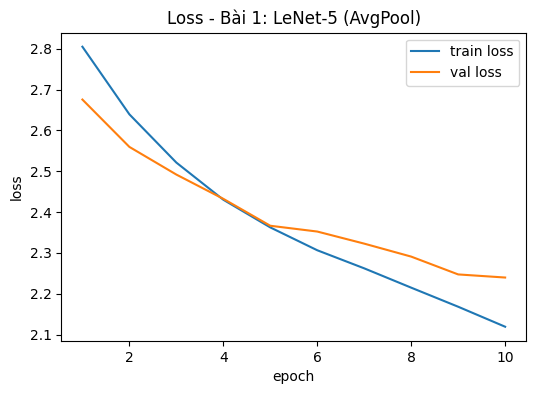


--- Kết quả trên tập Test (Bài 1: LeNet-5 (AvgPool)) ---
Accuracy  : 0.2776
Precision : 0.2673
Recall    : 0.2690
Macro-F1  : 0.2578

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.2192    0.1328    0.1654       241
        banh-hoi     0.2980    0.3657    0.3284       607
    banh-mi-chao     0.2893    0.4394    0.3489       289
        banh-tet     0.2082    0.1951    0.2014       364
 banh-trang-tron     0.1434    0.1294    0.1361       309
          banh-u     0.2571    0.1534    0.1922       176
        banh-uot     0.2955    0.2000    0.2386       560
       bap-nuong     0.2222    0.0979    0.1359       143
          bo-kho     0.4167    0.2219    0.2896       338
       bo-la-lot     0.4245    0.5153    0.4655       458
       bot-chien     0.2282    0.1232    0.1600       276
           ca-ri     0.1840    0.2281    0.2037       171
    canh-kho-qua     0.4359    0.5276    0.4774       290
   canh-khoai-mo     0.4932    0.7

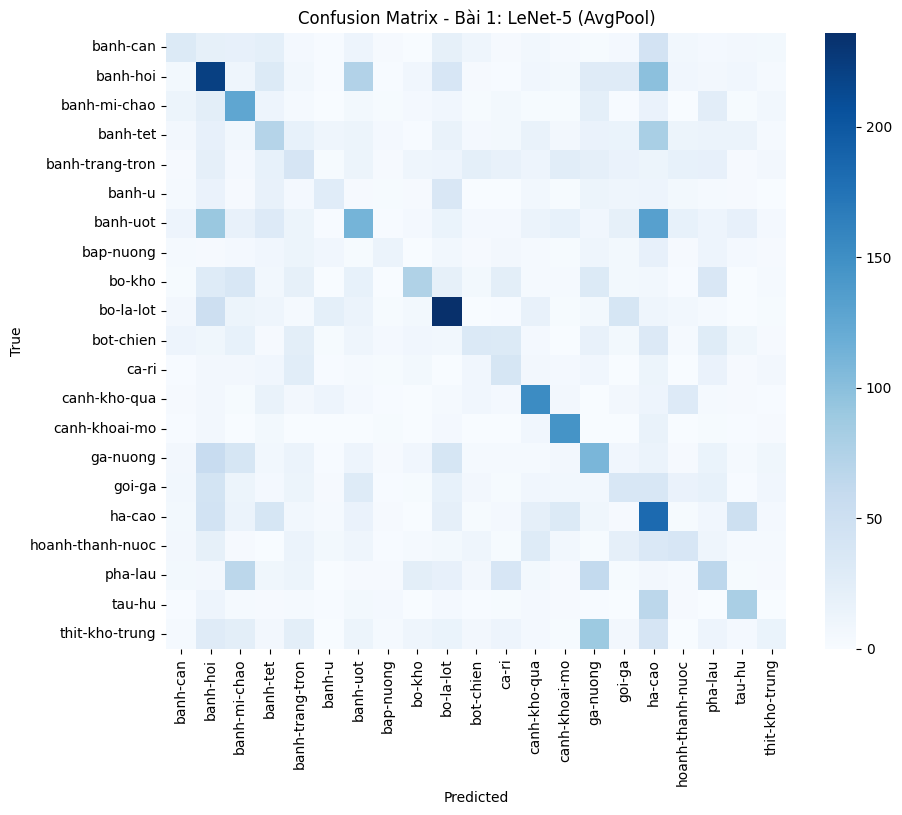


==================== Bài 1: LeNet-5 (MaxPool) ====================
Tổng tham số         : 339,421
Tham số được cập nhật: 339,421


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.8409/0.1353   val 2.7132/0.1882


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.5909/0.2108   val 2.4563/0.2171


...

epoch  8  train 2.1464/0.3363   val 2.2229/0.3277


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 2.0801/0.3579   val 2.1739/0.3367


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 2.0734/0.3596   val 2.1221/0.3685
Thời gian trung bình : 113.48 giây/epoch


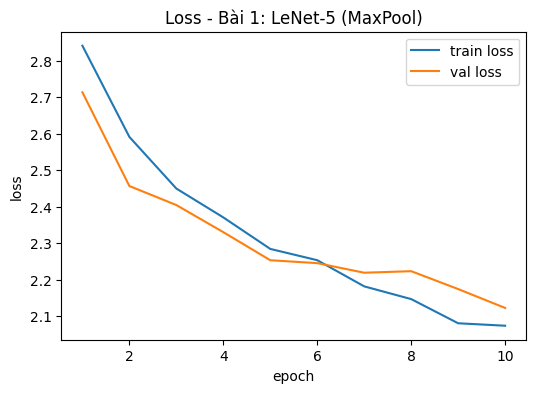


--- Kết quả trên tập Test (Bài 1: LeNet-5 (MaxPool)) ---
Accuracy  : 0.3150
Precision : 0.2956
Recall    : 0.2933
Macro-F1  : 0.2791

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.1633    0.2365    0.1932       241
        banh-hoi     0.3747    0.5025    0.4293       607
    banh-mi-chao     0.2269    0.4498    0.3016       289
        banh-tet     0.3179    0.3956    0.3525       364
 banh-trang-tron     0.2287    0.1392    0.1730       309
          banh-u     0.2931    0.0966    0.1453       176
        banh-uot     0.2581    0.3125    0.2827       560
       bap-nuong     0.0500    0.0070    0.0123       143
          bo-kho     0.3091    0.2899    0.2992       338
       bo-la-lot     0.4820    0.5568    0.5167       458
       bot-chien     0.1417    0.1268    0.1338       276
           ca-ri     0.3125    0.0292    0.0535       171
    canh-kho-qua     0.4520    0.5034    0.4763       290
   canh-khoai-mo     0.5604    0.7

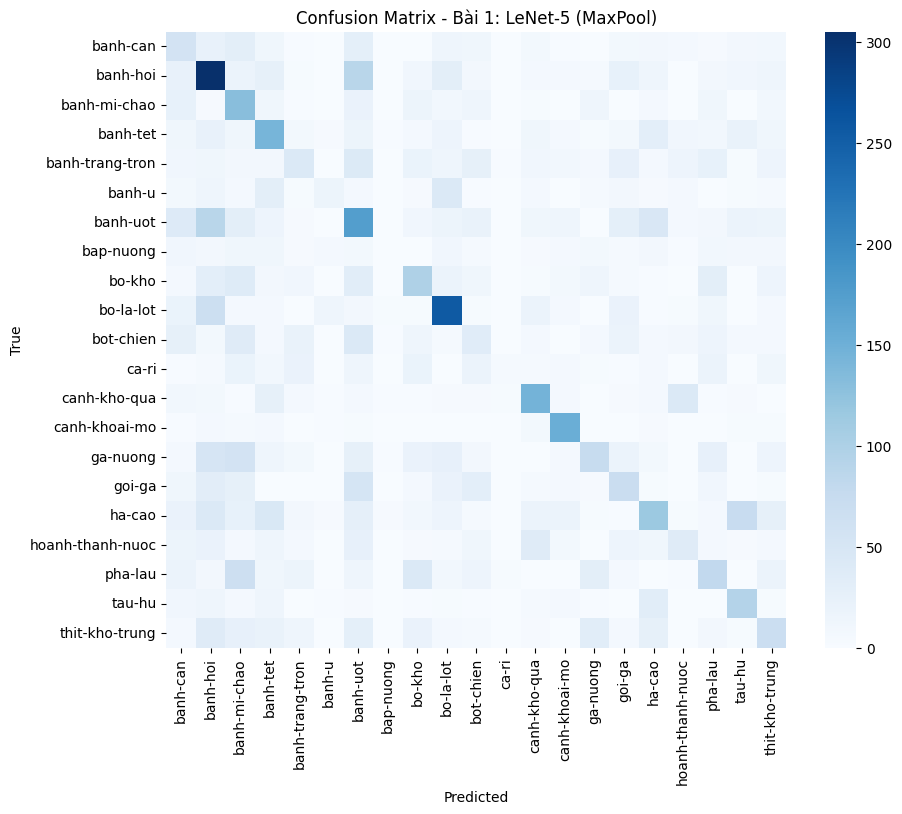

So sánh Bài 1 -> Macro-F1 AvgPool: 0.2578 | Macro-F1 MaxPool: 0.2791


In [ ]:
train_dl_64, val_dl_64, test_dl_64, CLASSES = get_dataloaders(IMG_SIZE=64)
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES), pool="avg")
rows, total = layer_table(lenet_avg, 64)
print(f"{'layer':<10}{'output':<16}{'tham số':>12}")

for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")

# Huấn luyện bản AvgPool và MaxPool để so sánh theo yêu cầu đề bài

f1_avg = run_experiment(lenet_avg, train_dl_64, val_dl_64, test_dl_64, CLASSES, lr=1e-3, title="Bài 1: LeNet-5 (AvgPool)")
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES), pool="max")
f1_max = run_experiment(lenet_max, train_dl_64, val_dl_64, test_dl_64, CLASSES, lr=1e-3, title="Bài 1: LeNet-5 (MaxPool)")
print(f"So sánh Bài 1 -> Macro-F1 AvgPool: {f1_avg:.4f} | Macro-F1 MaxPool: {f1_max:.4f}")

In [7]:
# =========================================
# BÀI 2: XÂY DỰNG MÔ HÌNH GOOGLENET RÚT GỌN
# =========================================

# Định nghĩa Inception block
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)

In [8]:
# Định nghĩa GoogLeNet rút gọn (3 Inception block + Global Average Pooling)
class MiniGoogLeNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 64x64 -> 32x32

        )
        # Block 1: ra 16 + 24 + 8 + 8 = 56 channel
        self.inc1 = InceptionBlock(32, 16, 16, 24, 4, 8, 8)
        self.pool1 = nn.MaxPool2d(2, 2)  # 32x32 -> 16x16
        # Block 2: ra 32 + 48 + 16 + 16 = 112 channel (y hệt B.4 Bước 3)
        self.inc2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
        self.pool2 = nn.MaxPool2d(2, 2)  # 16x16 -> 8x8
        # Block 3: ra 64 + 96 + 32 + 32 = 224 channel
        self.inc3 = InceptionBlock(112, 64, 48, 96, 16, 32, 32)
        # Dùng AdaptiveAvgPool2d(1) thay cho Flatten() theo yêu cầu Bài 2
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(224, num_classes)


    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.inc1(x))
        x = self.pool2(self.inc2(x))
        x = self.inc3(x)
        x = self.gap(x).flatten(1)
        return self.fc(x)


Đã dựng train_tf (augment=True) và eval_tf với cỡ ảnh 64x64.
Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...
Số lớp: 21 | Train: 9040 | Val: 1004 | Test: 6682
Sau stem                     (1, 32, 32, 32)
Sau Inception 1 (56 ch)      (1, 56, 32, 32)
Sau Inception 2 (112 ch)     (1, 112, 16, 16)
Sau Inception 3 (224 ch)     (1, 224, 8, 8)

==================== Bài 2: GoogLeNet rút gọn ====================
Tổng tham số         : 105,945
Tham số được cập nhật: 105,945


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.8940/0.1149   val 2.8466/0.1155


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.6558/0.1831   val 2.5568/0.2261


...

epoch  8  train 2.0445/0.3675   val 2.1100/0.3606


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 2.0032/0.3762   val 2.0280/0.3785


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 1.9516/0.3871   val 2.0205/0.3865
Thời gian trung bình : 109.81 giây/epoch


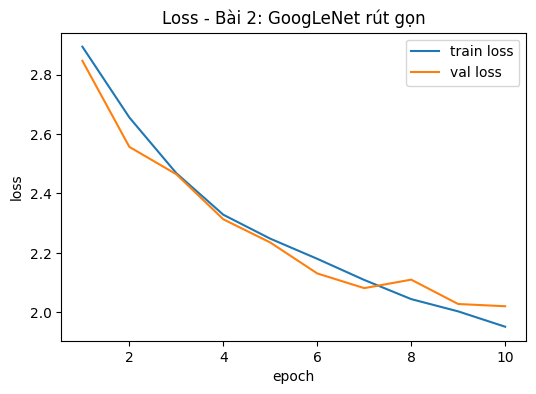


--- Kết quả trên tập Test (Bài 2: GoogLeNet rút gọn) ---
Accuracy  : 0.3391
Precision : 0.3898
Recall    : 0.3152
Macro-F1  : 0.3133

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.2951    0.0747    0.1192       241
        banh-hoi     0.2631    0.5964    0.3651       607
    banh-mi-chao     0.2834    0.5433    0.3725       289
        banh-tet     0.5467    0.3214    0.4048       364
 banh-trang-tron     0.2034    0.1942    0.1987       309
          banh-u     0.6000    0.1534    0.2443       176
        banh-uot     0.3137    0.2661    0.2879       560
       bap-nuong     0.5909    0.0909    0.1576       143
          bo-kho     0.4007    0.3521    0.3748       338
       bo-la-lot     0.5054    0.5109    0.5081       458
       bot-chien     0.3937    0.2283    0.2890       276
           ca-ri     0.3636    0.0702    0.1176       171
    canh-kho-qua     0.4622    0.5690    0.5100       290
   canh-khoai-mo     0.6852    0.7

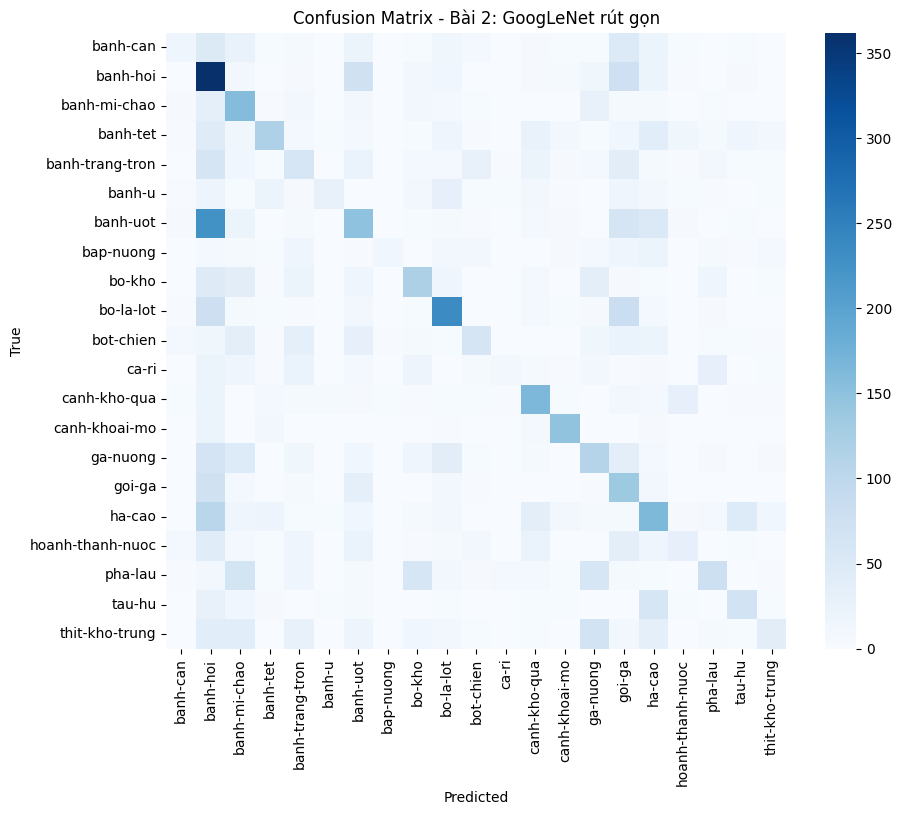

In [11]:
# --- Chạy Bài 2 ---
train_dl_64, val_dl_64, test_dl_64, CLASSES = get_dataloaders(IMG_SIZE=64)
googlenet = MiniGoogLeNet(in_ch=3, num_classes=len(CLASSES))
# In kiểm tra số channel sau mỗi Inception block trước khi huấn luyện
x_test = torch.rand(1, 3, 64, 64)
with torch.no_grad():
    s = googlenet.stem(x_test)
    b1_out = googlenet.inc1(s)
    b2_out = googlenet.inc2(googlenet.pool1(b1_out))
    b3_out = googlenet.inc3(googlenet.pool2(b2_out))
    show("Sau stem", s)
    show("Sau Inception 1 (56 ch)", b1_out)
    show("Sau Inception 2 (112 ch)", b2_out)
    show("Sau Inception 3 (224 ch)", b3_out)
f1_googlenet = run_experiment(googlenet, train_dl_64, val_dl_64, test_dl_64, CLASSES, lr=1e-3, title="Bài 2: GoogLeNet rút gọn")


In [16]:
# ==================================
# BÀI 3*: XÂY DỰNG MÔ HÌNH RESNET-18
# ==================================

# Định nghĩa BasicBlock
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()

        if stride != 1 or in_ch != out_ch:       # cần projection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)             # cộng trước
        return torch.relu(out)                   # ReLU sau



# Định nghĩa ResNet-18 theo bốn stage [2, 2, 2, 2] (Phần B.5 Bước 3)

class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod

    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride),
                             BasicBlock(out_ch, out_ch, 1))



    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))


Đã dựng train_tf (augment=False) và eval_tf với cỡ ảnh 96x96.
Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...
Số lớp: 21 | Train: 9040 | Val: 1004 | Test: 6682

==================== Bài 3*: ResNet-18 (Không Augmentation) ====================
Tổng tham số         : 11,187,285
Tham số được cập nhật: 11,187,285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.6405/0.1968   val 2.4467/0.2610


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.3432/0.2852   val 2.3080/0.2878


...

epoch  8  train 1.1410/0.6321   val 1.9023/0.4482


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 0.8517/0.7222   val 1.8721/0.4781


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 0.5869/0.8121   val 2.0078/0.4701
Thời gian trung bình : 103.21 giây/epoch


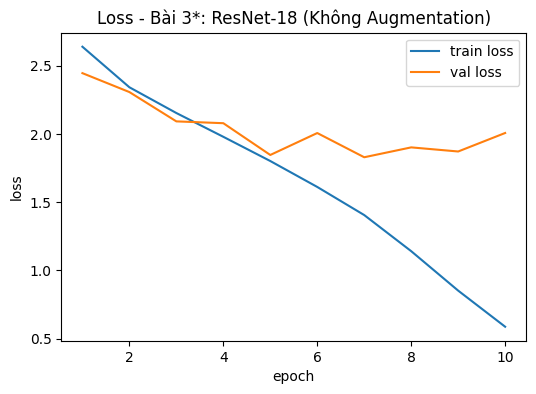


--- Kết quả trên tập Test (Bài 3*: ResNet-18 (Không Augmentation)) ---
Accuracy  : 0.3994
Precision : 0.4212
Recall    : 0.3910
Macro-F1  : 0.3955

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.3035    0.2531    0.2760       241
        banh-hoi     0.5137    0.3394    0.4087       607
    banh-mi-chao     0.3835    0.4498    0.4140       289
        banh-tet     0.4916    0.4011    0.4418       364
 banh-trang-tron     0.3059    0.2524    0.2766       309
          banh-u     0.3291    0.2955    0.3114       176
        banh-uot     0.3985    0.3786    0.3883       560
       bap-nuong     0.2844    0.2168    0.2460       143
          bo-kho     0.4267    0.4822    0.4528       338
       bo-la-lot     0.5800    0.6092    0.5942       458
       bot-chien     0.4150    0.3804    0.3970       276
           ca-ri     0.1833    0.1930    0.1880       171
    canh-kho-qua     0.5775    0.5138    0.5438       290
   canh-khoai-mo    

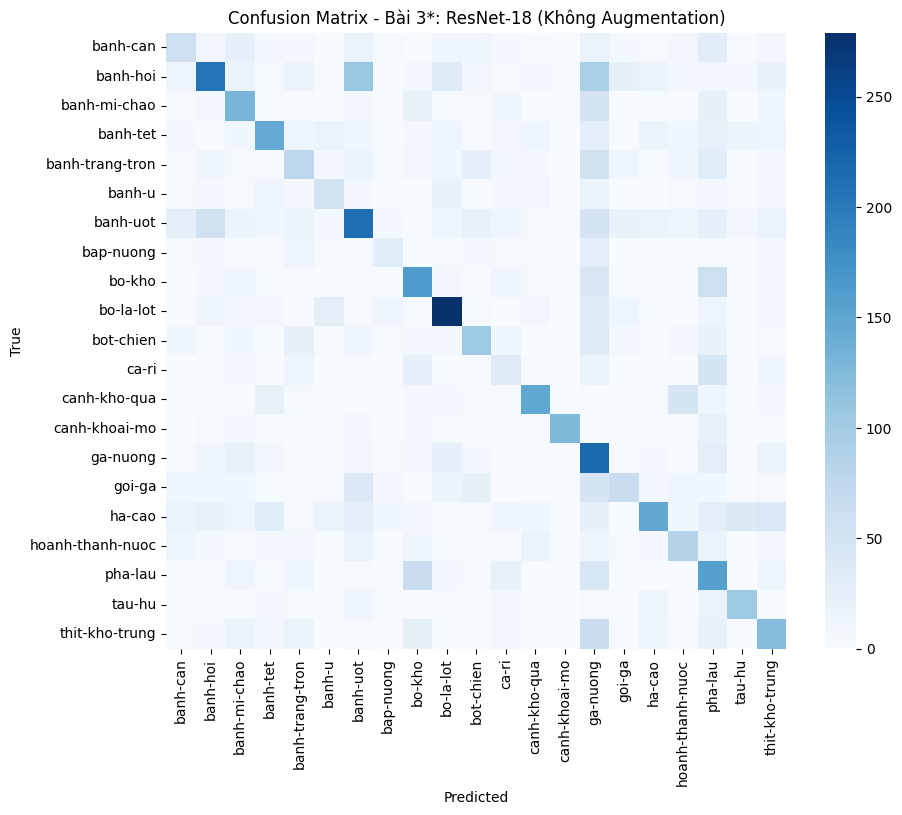

Đã dựng train_tf (augment=True) và eval_tf với cỡ ảnh 96x96.
Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...
Số lớp: 21 | Train: 9040 | Val: 1004 | Test: 6682

==================== Bài 3*: ResNet-18 (Có Augmentation) ====================
Tổng tham số         : 11,187,285
Tham số được cập nhật: 11,187,285


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7238/0.1836   val 2.5252/0.2440


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.4583/0.2483   val 2.4149/0.2480


...

epoch  8  train 1.8187/0.4282   val 1.8968/0.4153


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 1.7405/0.4482   val 1.8855/0.4193


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 1.6589/0.4808   val 1.6984/0.4781
Thời gian trung bình : 110.35 giây/epoch


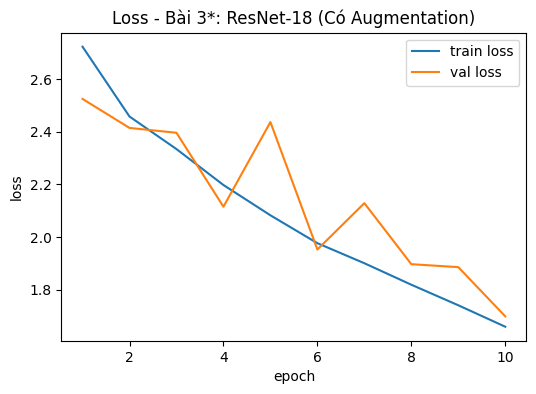


--- Kết quả trên tập Test (Bài 3*: ResNet-18 (Có Augmentation)) ---
Accuracy  : 0.4187
Precision : 0.4531
Recall    : 0.3892
Macro-F1  : 0.3911

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.3244    0.3029    0.3133       241
        banh-hoi     0.4185    0.7397    0.5345       607
    banh-mi-chao     0.7614    0.2318    0.3554       289
        banh-tet     0.5903    0.4670    0.5215       364
 banh-trang-tron     0.2905    0.2783    0.2843       309
          banh-u     0.3909    0.2443    0.3007       176
        banh-uot     0.3500    0.3125    0.3302       560
       bap-nuong     0.4426    0.1888    0.2647       143
          bo-kho     0.3386    0.5118    0.4075       338
       bo-la-lot     0.6256    0.5546    0.5880       458
       bot-chien     0.3189    0.3732    0.3439       276
           ca-ri     0.5000    0.0292    0.0552       171
    canh-kho-qua     0.4305    0.6621    0.5217       290
   canh-khoai-mo     0.

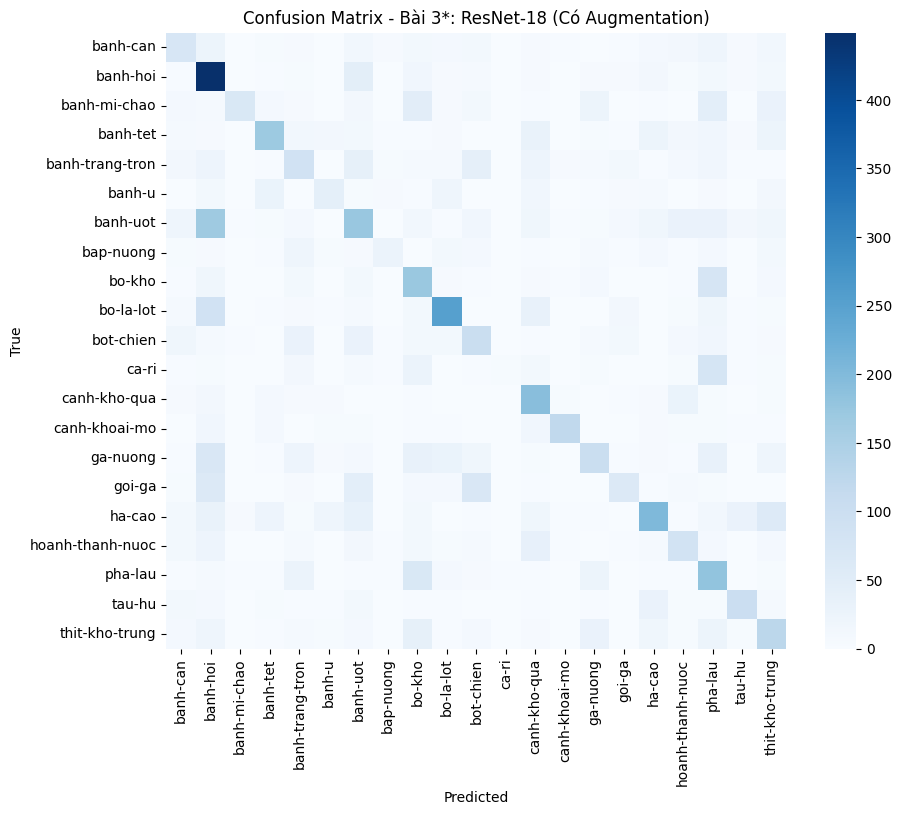

So sánh Bài 3* -> Macro-F1 Không Augment: 0.3955 | Có Augment: 0.3911


In [17]:
# Lần 1: Không có Augmentation

train_dl_96_noaug, val_dl_96, test_dl_96, _ = get_dataloaders(IMG_SIZE=96, HAS_TV=False)
r18_no_aug = ResNet18(num_classes=len(CLASSES))
f1_r18_noaug = run_experiment(r18_no_aug, train_dl_96_noaug, val_dl_96, test_dl_96, CLASSES, lr=1e-3, title="Bài 3*: ResNet-18 (Không Augmentation)")



# Lần 2: Có Augmentation

train_dl_96_aug, _, _, _ = get_dataloaders(IMG_SIZE=96, HAS_TV=True)
r18_aug = ResNet18(num_classes=len(CLASSES))
f1_r18_aug = run_experiment(r18_aug, train_dl_96_aug, val_dl_96, test_dl_96, CLASSES, lr=1e-3, title="Bài 3*: ResNet-18 (Có Augmentation)")

print(f"So sánh Bài 3* -> Macro-F1 Không Augment: {f1_r18_noaug:.4f} | Có Augment: {f1_r18_aug:.4f}")



In [18]:
# ======================================
# BÀI 4*: FINE-TUNE RESNET-50 PRETRAINED
# ======================================

from transformers import ResNetForImageClassification
# Định nghĩa model: backbone pretrained + classifier mới 21 lớp (Phần B.6 Bước 2)

class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)

        if freeze_backbone:                   # hai dòng này tạo ra feature extraction
            for p in self.resnet.parameters():
                p.requires_grad = False


    def forward(self, images):
        features = self.resnet(images).pooler_output    # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)     # [B, 2048]
        return self.classifier(features)                # [B, 21]

Đã dựng train_tf (augment=True) và eval_tf với cỡ ảnh 224x224.
Chưa có thư mục val/, tự động tách 10% từ train/ với seed=42...
Số lớp: 21 | Train: 9040 | Val: 1004 | Test: 6682


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

...

epoch  8  train 1.1417/0.6794   val 1.3189/0.6384


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 1.1047/0.6873   val 1.2780/0.6404


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 1.0567/0.7029   val 1.2566/0.6375
Thời gian trung bình : 148.25 giây/epoch


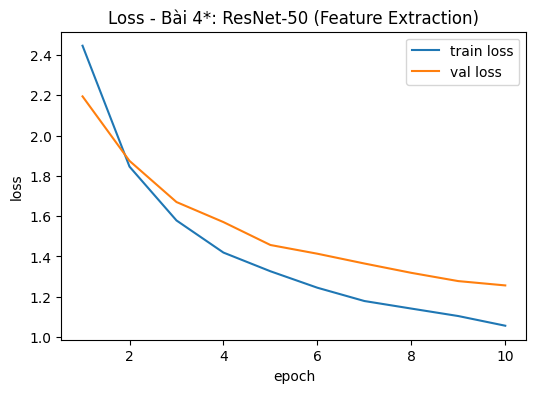


--- Kết quả trên tập Test (Bài 4*: ResNet-50 (Feature Extraction)) ---
Accuracy  : 0.5994
Precision : 0.6168
Recall    : 0.6041
Macro-F1  : 0.5962

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.5739    0.6763    0.6210       241
        banh-hoi     0.6563    0.4876    0.5595       607
    banh-mi-chao     0.6087    0.7266    0.6625       289
        banh-tet     0.9137    0.4945    0.6417       364
 banh-trang-tron     0.6966    0.5275    0.6004       309
          banh-u     0.7197    0.6420    0.6787       176
        banh-uot     0.5293    0.4036    0.4580       560
       bap-nuong     0.8188    0.7902    0.8043       143
          bo-kho     0.4473    0.6657    0.5351       338
       bo-la-lot     0.6315    0.7183    0.6721       458
       bot-chien     0.4568    0.6123    0.5232       276
           ca-ri     0.2353    0.0234    0.0426       171
    canh-kho-qua     0.7730    0.7517    0.7622       290
   canh-khoai-mo    

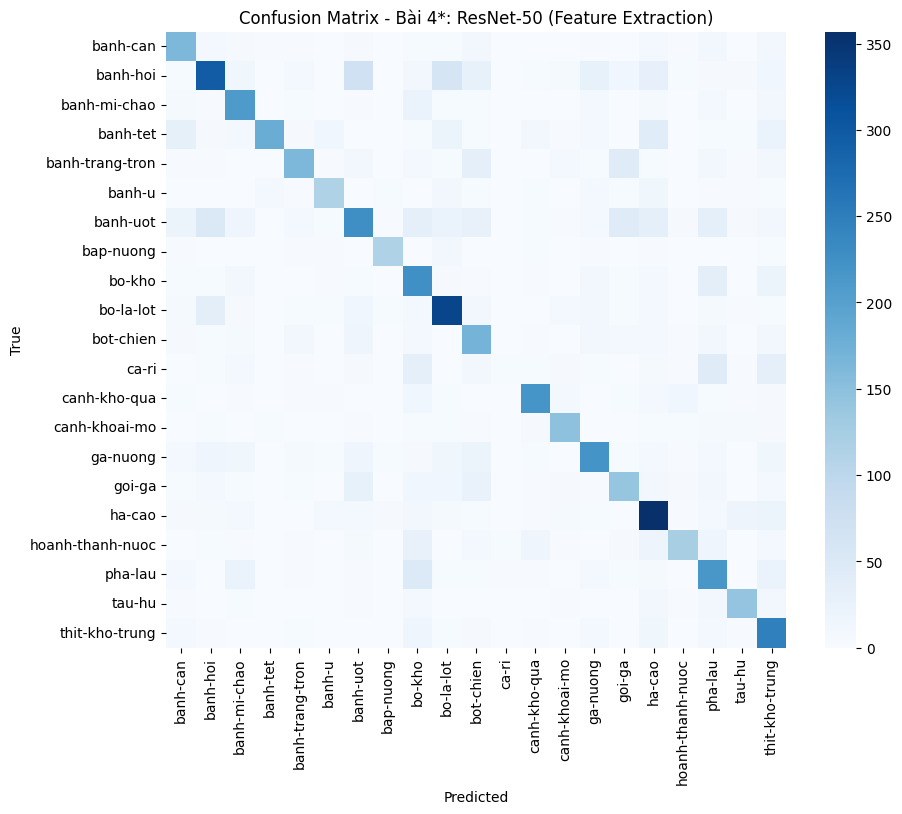

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]


==================== Bài 4*: ResNet-50 (Fine-tuning) ====================
Tổng tham số         : 23,551,061
Tham số được cập nhật: 23,551,061


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.7378/0.1903   val 2.2676/0.4253


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch  8  train 0.3312/0.8991   val 0.4038/0.8655


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  9  train 0.2783/0.9149   val 0.3803/0.8725


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 10  train 0.2510/0.9222   val 0.3917/0.8745
Thời gian trung bình : 173.83 giây/epoch


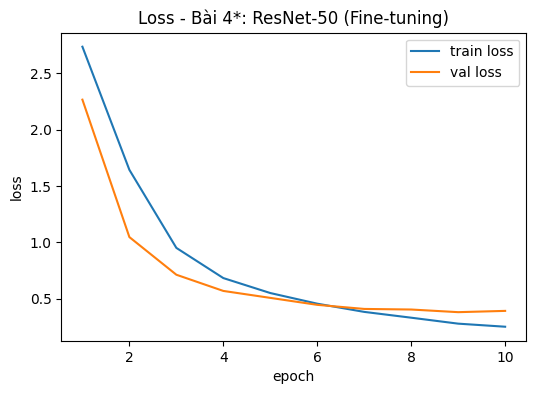


--- Kết quả trên tập Test (Bài 4*: ResNet-50 (Fine-tuning)) ---
Accuracy  : 0.8482
Precision : 0.8476
Recall    : 0.8515
Macro-F1  : 0.8478

Bảng F1 từng lớp:
                  precision    recall  f1-score   support

        banh-can     0.8178    0.9129    0.8627       241
        banh-hoi     0.8586    0.8600    0.8593       607
    banh-mi-chao     0.9064    0.9377    0.9218       289
        banh-tet     0.9759    0.7775    0.8654       364
 banh-trang-tron     0.9132    0.8511    0.8811       309
          banh-u     0.7810    0.9318    0.8497       176
        banh-uot     0.7846    0.7804    0.7825       560
       bap-nuong     0.9267    0.9720    0.9488       143
          bo-kho     0.8150    0.7692    0.7915       338
       bo-la-lot     0.8760    0.9410    0.9074       458
       bot-chien     0.8231    0.8261    0.8246       276
           ca-ri     0.6078    0.5439    0.5741       171
    canh-kho-qua     0.9320    0.9448    0.9384       290
   canh-khoai-mo     0.9479

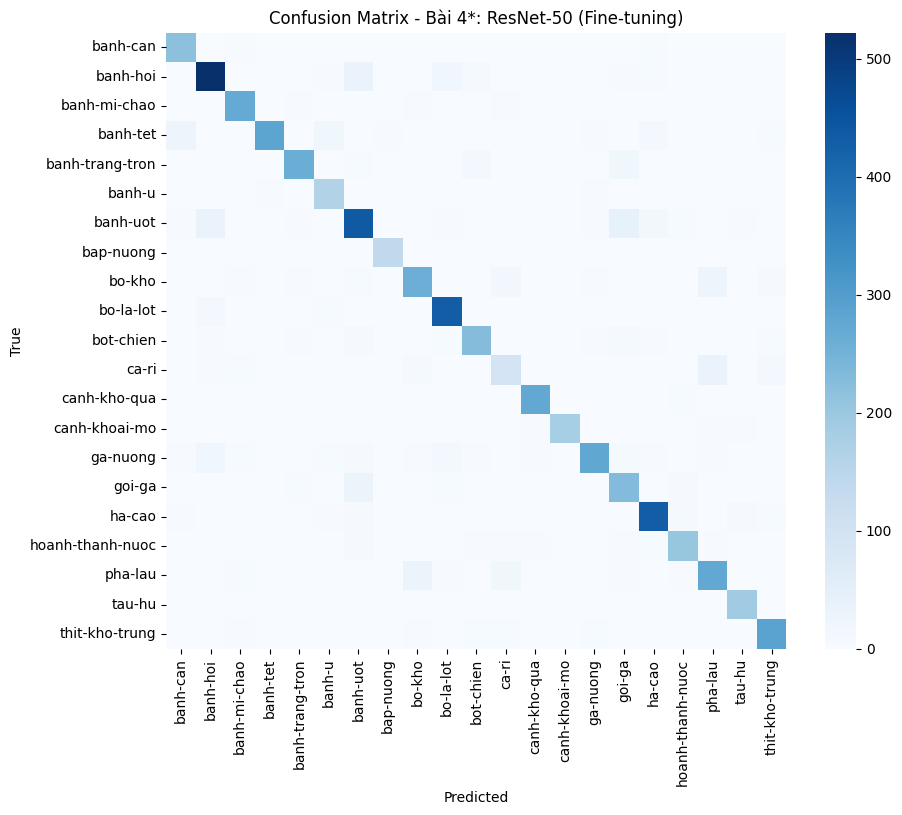

So sánh Bài 4* -> Macro-F1 Feature Extraction: 0.5962 | Fine-tuning: 0.8478


In [19]:
train_dl_224, val_dl_224, test_dl_224, _ = get_dataloaders(IMG_SIZE=224, HAS_TV=True)

# Chế độ 1: Feature Extraction (đóng băng backbone, lr = 1e-3)

resnet50_fe = PretrainedResnet(num_classes=len(CLASSES), freeze_backbone=True)

f1_r50_fe = run_experiment(resnet50_fe, train_dl_224, val_dl_224, test_dl_224, CLASSES, lr=1e-3, title="Bài 4*: ResNet-50 (Feature Extraction)")



# Chế độ 2: Fine-tuning toàn mạng (mở khoá backbone, lr = 1e-4)

resnet50_ft = PretrainedResnet(num_classes=len(CLASSES), freeze_backbone=False)

f1_r50_ft = run_experiment(resnet50_ft, train_dl_224, val_dl_224, test_dl_224, CLASSES, lr=1e-4, title="Bài 4*: ResNet-50 (Fine-tuning)")

print(f"So sánh Bài 4* -> Macro-F1 Feature Extraction: {f1_r50_fe:.4f} | Fine-tuning: {f1_r50_ft:.4f}")